# Level versus shape

A day can be wrong in two different ways.

**Level** is the day's average. If every hour is forecast 40 g/kWh too clean, the shape of the day is right and the level is wrong. MAE is about 40. A decision that only needs the order of hours, such as "run in the cleanest four hours," still works.

**Shape** is what is left after each series has its own mean removed. Shape MAE is the average miss of that leftover. A forecast with the right average and the noon dip in the wrong place has a small level error and a large shape MAE.

Complete local days only. The holdout starts and ends in the middle of a Pacific afternoon, so the first and last dates are dropped.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

from src.carbon_data import load_model_frame
from src.modeling import (
    TARGET,
    day_scores,
    error_components,
    fixed_forecasts,
    local_day_labels,
    train_test_split,
)

frame = load_model_frame()
train, test = train_test_split(frame)
assert train.index.max() < test.index.min()
forecasts = fixed_forecasts(train, test)
print(
    f"train through {train.index.max():%Y-%m-%d %H} UTC; "
    f"holdout {test.index.min():%Y-%m-%d %H} to {test.index.max():%Y-%m-%d %H} UTC "
    f"({len(test)} hours)"
)
print(
    f"mean carbon {train[TARGET].mean():.0f} g/kWh in training, "
    f"{test[TARGET].mean():.0f} on the holdout"
)
print("forecasts:", ", ".join(forecasts))


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

train through 2026-09-20 22 UTC; holdout 2026-09-20 23 to 2026-10-18 23 UTC (673 hours)
mean carbon 103 g/kWh in training, 172 on the holdout
forecasts: hour-of-day mean, yesterday, same hour, day-ahead ridge, day-ahead tree, previous hour


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

In [2]:
pieces = []
for name, predicted in forecasts.items():
    daily = day_scores(test, predicted)
    pieces.append(
        {
            "model": name,
            "days": len(daily),
            "mae": daily["mae"].mean(),
            "abs_level_error": daily["level_error"].abs().mean(),
            "shape_mae": daily["shape_mae"].mean(),
            "level_share_of_mae": daily["level_error"].abs().mean() / daily["mae"].mean(),
        }
    )
pieces = pd.DataFrame(pieces).set_index("model").loc[list(forecasts)]
print(f"{int(pieces['days'].iloc[0])} complete local days")
pieces.round(3)


27 complete local days


,days,mae,abs_level_error,shape_mae,level_share_of_mae
model,,,,,
hour-of-day mean,27,70.931,69.985,24.485,0.987
"yesterday, same hour",27,26.437,20.696,16.682,0.783
day-ahead ridge,27,24.887,19.672,16.242,0.790
day-ahead tree,27,30.717,26.278,17.356,0.856
previous hour,27,10.057,3.820,9.016,0.380


## One day at a time, day-ahead ridge

Each point is a complete day on the holdout. The left panel asks whether a bad MAE is mostly a bad level. The right panel asks whether a bad shape is what makes the cleanest-four-hour choice expensive. Regret is defined in the next notebook: extra g/kWh from running in the hours the forecast called clean.

On 15 of 27 days, the level miss is larger than the shape miss.
Mean level error -6.5 g/kWh (negative means the forecast was too clean).


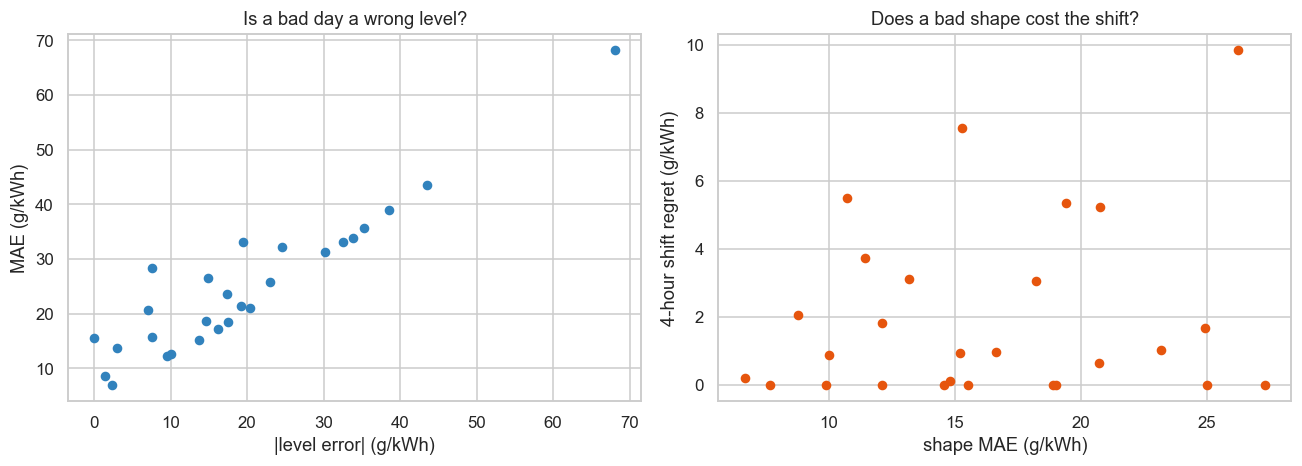

In [3]:
daily = day_scores(test, forecasts["day-ahead ridge"])
print(
    f"On {int((daily['level_error'].abs() > daily['shape_mae']).sum())} of {len(daily)} days, "
    "the level miss is larger than the shape miss."
)
print(
    f"Mean level error {daily['level_error'].mean():.1f} g/kWh "
    "(negative means the forecast was too clean)."
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].scatter(daily["level_error"].abs(), daily["mae"], s=28, color="#3182bd")
axes[0].set_xlabel("|level error| (g/kWh)")
axes[0].set_ylabel("MAE (g/kWh)")
axes[0].set_title("Is a bad day a wrong level?")
axes[1].scatter(daily["shape_mae"], daily["regret_4h"], s=28, color="#e6550d")
axes[1].set_xlabel("shape MAE (g/kWh)")
axes[1].set_ylabel("4-hour shift regret (g/kWh)")
axes[1].set_title("Does a bad shape cost the shift?")
fig.tight_layout()
